Here we construct data for a many possible Cayley Graphs. Maybe we create a class for a group. Then, the class will contain things like

In [ ]:
"""class Group():
    def __init__(self, elements, mul):
        self.elements = elements
        self.mul = mul
        self.
        self.identity = identity
        self.generators = generators
        self.labels = labels
        self.cayley_graph = self.build_cayley_graph()
        self.cayley_graph_layout = self.cayley_graph_layout()

class GNNLayer(nn.Module):

    def __init__(self, input_dim, output_dim):
      #We are going to implement a simple GNN layer that performs a linear transformation followed by a neighborhood aggregation.
      super().__init__()
      self.input_dim = input_dim
      self.output_dim = output_dim
      self.W_self = nn.Linear(input_dim, output_dim,bias = False)
      self.W_neigh = nn.Linear(input_dim, output_dim, bias = False)
#shape of node_feats is (input_dim, N) because we are assuming that the feature vectors are columns.
    def forward(self, node_feats, adj_matrix):
      neigh_col = node_feats @ adj_matrix # (input_dim, N) @ (N, N) = (input_dim, N)
      H_row = node_feats.t()                    # (N, F_in)
      neigh_row = neigh_col.t()                 # (N, F_in)

      self_part = self.W_self(H_row)            # (N, F_out)
      neigh_part = self.W_neigh(neigh_row)      # (N, F_out)

      out_row = self_part + neigh_part          # (N, F_out)
      out_col = out_row.t()           
      return out_col
      """

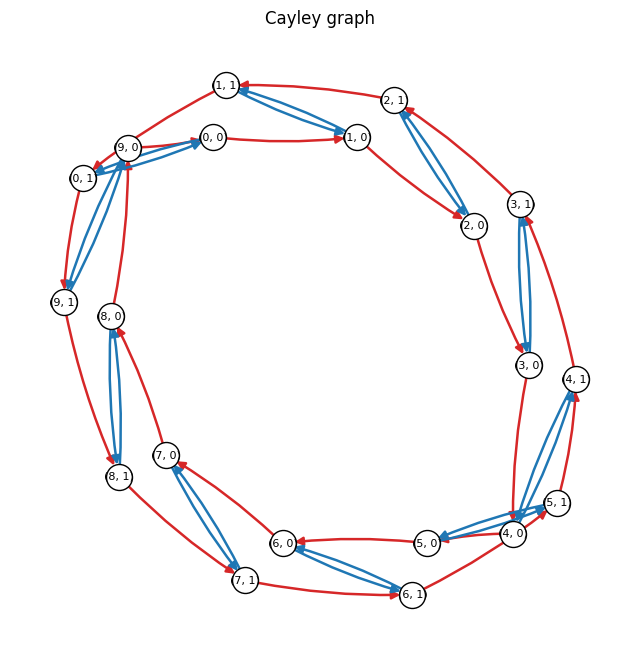

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

def make_Dn(n):
    # Dihedral group D_n elements as (k, f): k in Z_n, f in {0,1}
    # Multiplication: (k1,f1)*(k2,f2) = (k1 + (-1)^f1 * k2 mod n, f1 xor f2)
    elements = [(k, f) for k in range(n) for f in (0, 1)]

    def mul(a, b):
        k1, f1 = a
        k2, f2 = b
        k = (k1 + ((-1) ** f1) * k2) % n
        f = f1 ^ f2
        return (int(k), int(f))

    identity = (0, 0)
    gens = [("r", (1, 0)), ("s", (0, 1))]
    return elements, mul, gens, identity


def _normalize_generators(generators):
    # Accept either [g1, g2, ...] or [("name", g1), ("name", g2), ...]
    if not generators:
        return [], []
    if isinstance(generators[0], tuple) and len(generators[0]) == 2 and isinstance(generators[0][0], str):
        labels = [lab for lab, _ in generators]
        gens = [g for _, g in generators]
    else:
        gens = list(generators)
        labels = [str(g) for g in gens]
    return gens, labels


def build_cayley_graph(elements, mul, generators):
    gens, labels = _normalize_generators(generators)

    G = nx.DiGraph()
    G.add_nodes_from(elements)
    for a in elements:
        for g, lab in zip(gens, labels):
            b = mul(a, g)
            G.add_edge(a, b, label=lab)
    return G


def cayley_graph_layout(elements, generators, mul, identity, seed=0):
    gens, _ = _normalize_generators(generators)
    G = build_cayley_graph(elements, mul, generators)

    pos0 = nx.spectral_layout(G, dim=2)
    k = 1.0 / np.sqrt(max(1, G.number_of_nodes()))
    pos = nx.spring_layout(G, seed=seed, pos=pos0, k=k, iterations=2000)

    # Translate so identity sits at the origin
    p_id = np.array(pos[identity], dtype=float)
    for v in pos:
        pos[v] = np.array(pos[v], dtype=float) - p_id

    # Rotate so the first generator points along +x
    if gens:
        n0 = mul(identity, gens[0])
        v = np.array(pos[n0], dtype=float)
        ang = np.arctan2(v[1], v[0])
        c, s = np.cos(-ang), np.sin(-ang)
        R = np.array([[c, -s], [s, c]], dtype=float)
        for x in pos:
            pos[x] = R @ np.array(pos[x], dtype=float)

    return G, pos


def draw_cayley_graph(elements, generators, mul, identity, seed=0, figsize=(8, 8)):
    G, pos = cayley_graph_layout(elements, generators, mul, identity, seed=seed)
    _, labels = _normalize_generators(generators)

    plt.figure(figsize=figsize)
    nx.draw_networkx_nodes(G, pos, node_size=350, node_color="white", edgecolors="black")
    nx.draw_networkx_labels(G, pos, {n: str(n) for n in G.nodes()}, font_size=8)

    edges = list(G.edges(data=True))
    cmap = ["#d62728", "#1f77b4", "#2ca02c", "#9467bd", "#ff7f0e"]

    for i, lab in enumerate(labels):
        edgelist = [(u, v) for u, v, d in edges if d.get("label") == lab]
        if not edgelist:
            continue
        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=edgelist,
            edge_color=cmap[i % len(cmap)],
            arrows=True,
            arrowsize=12,
            width=1.8,
            connectionstyle="arc3,rad=0.06",
        )

    plt.axis("off")
    plt.title("Cayley graph")
    plt.show()


# Example: draw D_n
n = 10
elements, mul, gens, identity = make_Dn(n)
draw_cayley_graph(elements, gens, mul, identity, seed=7)

What is the code below?

Now we want to do standard message-passing and try to predict various properties of groups. We can use pytorch geometric for this. Let's see how we just draw a graph here.

In [5]:
import torch
import torch_geometric


. @Oxford/Hilary/Geometric deep learning/Mini-project-code/torch-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
edge_index = torch.tensor([[0, 1, 1, 2],
                           [1, 0, 2, 1]], dtype=torch.long)
x = torch.tensor([[-1], [0], [1]], dtype=torch.float)

data = Data(x=x, edge_index=edge_index)

NameError: name 'torch' is not defined

This is some code I wrote before. 

In [ ]:
from collections import deque
import itertools
def compose(p,q):
    return tuple(p[q[i]-1] for i in range (len(p)))

def inv(p):
    n = len(p)
    invp = [0]*n
    for i in range(n):
        invp[p[i]-1] = i+1
    return tuple(invp)

def subgroup_generated_by(generators):
    n = len(generators[0])
    G = set()
    q = deque()
    e = tuple(range(1,n+1)) 
    G.add(e)
    q.append(e) 
    while q:
        g = q.popleft()
        for gen in generators:
            h = compose(g, gen)
            if h not in G:
                G.add(h); q.append(h)
            h2 = compose(g, inv(gen))
            if h2 not in G:
                G.add(h2); q.append(h2)
    return list(G)

def edges_from_generators(generators, undirected=True, self_loops=False):
    n = len(generators[0])
    G = set()
    edges = []
    q = deque()
    e = tuple(range(1,n+1))
    G.add(e)
    q.append(e)
    while q:
        g = q.popleft()
        for gen in generators:
            h = compose(g, gen)
            edges.append((g,h))
            if h not in G:
                G.add(h); q.append(h)
    return edges

#def plotgraph(edges):
    plt.axis("off")
    plt.show()

#This is a function to make permutation from cycle notation.

def cycle_perm(ltuples,n): #Here, we will not give length 1 tuples because of python syntax issues.
    perm = list(range(1,n+1))
    for t in ltuples:
        for i in range(len(t)-1):
            perm[t[i]-1] = t[i+1]
        perm[t[len(t)-1]-1] = t[0]
    return tuple(perm)